# model_benchmark 結果可視化

VAD・話者分離・音声認識・ベクトル検索の各ベンチマーク結果を比較する．
`EXPERIMENT`を切り替えることで，`ex001_model_benchmark`・`ex002_model_benchmark`等の結果を選べる．

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

EXPERIMENT = "ex002_model_benchmark"  # "ex001_model_benchmark" に切り替えて再実行することもできる
OUTPUT_DIR = Path("outputs") / EXPERIMENT


def load_metrics(task: str) -> dict:
    """指定タスクの全手法のmetrics.jsonを読み込む関数．"""
    result = {}
    task_dir = OUTPUT_DIR / task
    if not task_dir.exists():
        return result
    for method_dir in sorted(task_dir.iterdir()):
        metrics_path = method_dir / "metrics.json"
        if metrics_path.exists():
            result[method_dir.name] = json.loads(metrics_path.read_text(encoding="utf-8"))
    return result

## VAD(音声区間検出)

/tmp/ipykernel_2963455/379618777.py:11: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/379618777.py:11: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


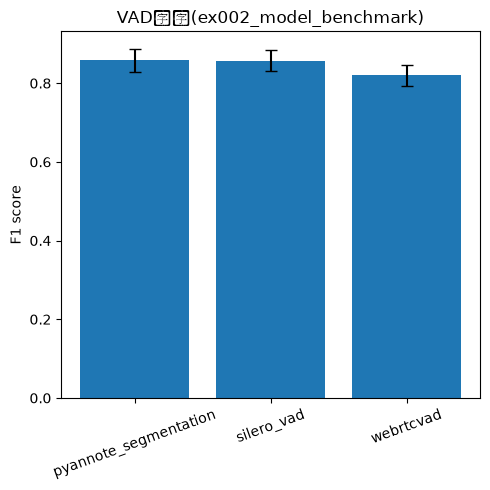

In [2]:
vad_metrics = load_metrics("vad")
methods = list(vad_metrics.keys())
f1_scores = [vad_metrics[m]["mean"]["f1"] for m in methods]
f1_stds = [vad_metrics[m].get("std", {}).get("f1", 0.0) for m in methods]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(methods, f1_scores, yerr=f1_stds, capsize=4)
ax.set_ylabel("F1 score")
ax.set_title(f"VAD比較({EXPERIMENT})")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "vad" / "comparison.png")
plt.show()

## 話者分離(DER)

/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 12411 (\N{HIRAGANA LETTER HO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 12393 (\N{HIRAGANA LETTER DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 33391 (\N{CJK UNIFIED IDEOGRAPH-826F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 35441 (\N{CJK UNIFIED IDEOGRAPH-8A71}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2640336568.py:11: UserWarning: Glyph 32773 (\N{CJK UNIFIED IDEOGRAPH-8005}) mi

/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12411 (\N{HIRAGANA LETTER HO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12393 (\N{HIRAGANA LETTER DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-

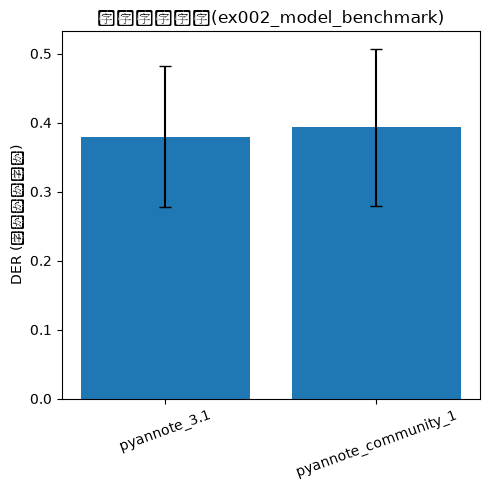

In [3]:
diarization_metrics = load_metrics("diarization")
methods = list(diarization_metrics.keys())
der_scores = [diarization_metrics[m]["mean_der"] for m in methods]
der_stds = [diarization_metrics[m].get("std_der", 0.0) for m in methods]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(methods, der_scores, yerr=der_stds, capsize=4)
ax.set_ylabel("DER (低いほど良い)")
ax.set_title(f"話者分離比較({EXPERIMENT})")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "diarization" / "comparison.png")
plt.show()

## 音声認識(CER)

/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 12411 (\N{HIRAGANA LETTER HO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 12393 (\N{HIRAGANA LETTER DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 33391 (\N{CJK UNIFIED IDEOGRAPH-826F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 38899 (\N{CJK UNIFIED IDEOGRAPH-97F3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/387934496.py:11: UserWarning: Glyph 22768 (\N{CJK UNIFIED IDEOGRAPH-58F0}) missing f

/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38899 (\N{CJK UNIFIED IDEOGRAPH-97F3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22768 (\N{CJK UNIFIED IDEOGRAPH-58F0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35469 (\N{CJK UNIFIED IDEOGRAPH-8A8D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35672 (\N{CJK UNIFIED IDEOGRAPH-8B58}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


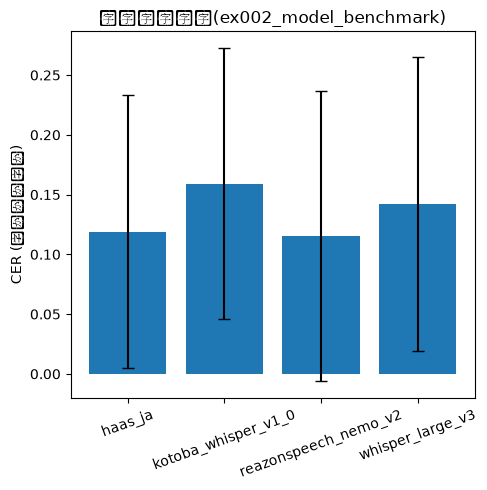

In [4]:
asr_metrics = load_metrics("asr")
methods = list(asr_metrics.keys())
cer_scores = [asr_metrics[m]["mean_cer"] for m in methods]
cer_stds = [asr_metrics[m].get("std_cer", 0.0) for m in methods]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(methods, cer_scores, yerr=cer_stds, capsize=4)
ax.set_ylabel("CER (低いほど良い)")
ax.set_title(f"音声認識比較({EXPERIMENT})")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "asr" / "comparison.png")
plt.show()

## ベクトル検索(Recall@k, MRR)

/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 22475 (\N{CJK UNIFIED IDEOGRAPH-57CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 12417 (\N{HIRAGANA LETTER ME}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 36796 (\N{CJK UNIFIED IDEOGRAPH-8FBC}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 12415 (\N{HIRAGANA LETTER MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 12514 (\N{KATAKANA LETTER MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 12487 (\N{KATAKANA LETTER DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/2884876054.py:10: UserWarning: Glyph 12523 (\N{KATAKANA LETTER RU}) missing from font

/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22475 (\N{CJK UNIFIED IDEOGRAPH-57CB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12417 (\N{HIRAGANA LETTER ME}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36796 (\N{CJK UNIFIED IDEOGRAPH-8FBC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12415 (\N{HIRAGANA LETTER MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3

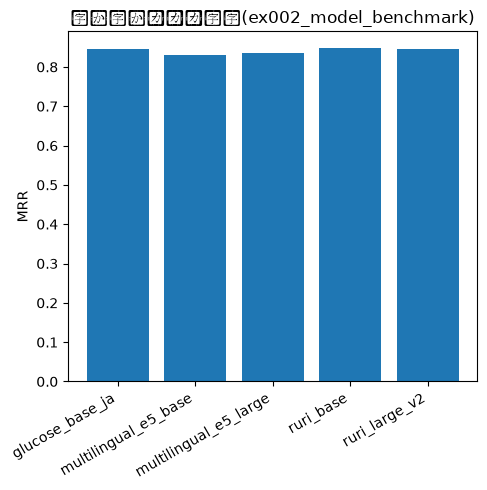

In [5]:
embedding_metrics = load_metrics("embedding")
methods = [m for m in embedding_metrics.keys()]
mrr_scores = [embedding_metrics[m]["mrr"] for m in methods]

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(methods, mrr_scores)
ax.set_ylabel("MRR")
ax.set_title(f"埋め込みモデル比較({EXPERIMENT})")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "embedding" / "comparison.png")
plt.show()

## ex001とex002の比較(データ拡充前後での順位の変化)

/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 12411 (\N{HIRAGANA LETTER HO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 12393 (\N{HIRAGANA LETTER DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 33391 (\N{CJK UNIFIED IDEOGRAPH-826F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 12469 (\N{KATAKANA LETTER SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2963455/3903539481.py:27: UserWarning: Glyph 12531 (\N{KATAKANA LETTER N}) missing from font(s

/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20302 (\N{CJK UNIFIED IDEOGRAPH-4F4E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12356 (\N{HIRAGANA LETTER I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12411 (\N{HIRAGANA LETTER HO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12393 (\N{HIRAGANA LETTER DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/user/workspace/EchoMindServer/.venv_ml/lib/python3.11/site-

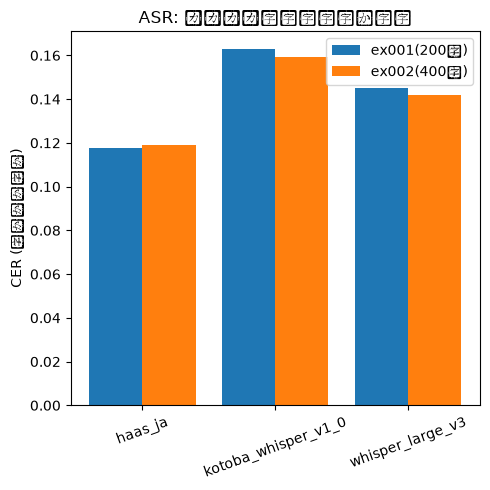

In [6]:
def load_metrics_for(experiment: str, task: str) -> dict:
    """指定した実験・タスクの全手法のmetrics.jsonを読み込む関数．"""
    result = {}
    task_dir = Path("outputs") / experiment / task
    if not task_dir.exists():
        return result
    for method_dir in sorted(task_dir.iterdir()):
        metrics_path = method_dir / "metrics.json"
        if metrics_path.exists():
            result[method_dir.name] = json.loads(metrics_path.read_text(encoding="utf-8"))
    return result


asr_ex001 = load_metrics_for("ex001_model_benchmark", "asr")
asr_ex002 = load_metrics_for("ex002_model_benchmark", "asr")
common_methods = [m for m in asr_ex002 if m in asr_ex001]

fig, ax = plt.subplots(figsize=(5, 5))
x = range(len(common_methods))
ax.bar([i - 0.2 for i in x], [asr_ex001[m]["mean_cer"] for m in common_methods], width=0.4, label="ex001(200件)")
ax.bar([i + 0.2 for i in x], [asr_ex002[m]["mean_cer"] for m in common_methods], width=0.4, label="ex002(400件)")
ax.set_xticks(list(x))
ax.set_xticklabels(common_methods, rotation=20)
ax.set_ylabel("CER (低いほど良い)")
ax.set_title("ASR: サンプル数拡大前後の比較")
ax.legend()
plt.tight_layout()
plt.savefig(Path("outputs/ex002_model_benchmark/asr") / "comparison_vs_ex001.png")
plt.show()